# Compare fixed brain-vasculature clustering workflows with GAUGE

**Your task.** Compare three prespecified Scanpy workflows on the same 2,500 human brain-vasculature cells. Decide whether a finer partition earns enough additional molecular support to justify keeping more groups. Then inspect the sizes of the groups and compare where the candidate labels differ.

The teaching asset contains raw counts for 26,666 genes from a fixed sample of the vasculature study (GSE256493). Donor and biological labels were excluded from this teaching asset. The three candidates differ in graph and clustering settings. All candidates share one molecular representation for evaluation.

## 0. Install GAUGE and place the data beside this notebook

Use Python 3.10 or newer. In a terminal on macOS or Linux, create and activate an environment.

```bash
python -m venv .venv
source .venv/bin/activate
```

In Windows PowerShell, activate it with `.venv\Scripts\Activate.ps1`.

Install the software and tutorial dependencies from the public GAUGE repository. If you already have a checkout, run the install command from its root.

```bash
git clone https://github.com/zhanglabtools/gauge-sc.git
cd gauge-sc
python -m pip install ".[tutorial]" jupyterlab
```

To install from a downloaded wheel, pass its local path with the tutorial extra. This example uses version `0.1.0a2`.

```bash
python -m pip install "./gauge_sc-0.1.0a2-py3-none-any.whl[tutorial]" jupyterlab
```

Download **`vasculature.h5ad`** (about 14.5 MB) from [tutorial-data-v1](https://github.com/zhanglabtools/gauge-sc/releases/tag/tutorial-data-v1) and put it beside this notebook. You can also run this command from the notebook folder.

```bash
curl -fLO https://github.com/zhanglabtools/gauge-sc/releases/download/tutorial-data-v1/vasculature.h5ad
```

From that folder, run `jupyter lab`, open this notebook and select the installed Python environment as its kernel. If the data is elsewhere, set `data_dir` below to its containing directory. GAUGE verifies the pinned local file. The first cell should print **2,500 cells × 26,666 features**.

In [1]:
import os
from pathlib import Path

import gauge_sc as gauge

data_dir = Path(os.environ.get("GAUGE_TUTORIAL_DATA") or ".")
source = gauge.datasets.load_example("vasculature", data_dir=data_dir, download=False)
print(f"GAUGE {gauge.__version__} · {source.n_obs:,} cells × {source.n_vars:,} features")

Matplotlib is building the font cache; this may take a moment.


GAUGE 0.1.0a2 · 2,500 cells × 26,666 features


## 1. Fix the molecular representation and generate three candidates

Normalize each cell to 10,000 total counts, apply `log1p`, choose 2,000 highly variable genes and compute 30 principal components. The PCs are stored in `obsm["X_pca"]` and held fixed across all comparisons.

Each workflow builds its own nearest-neighbor graph on those same PCs and runs Leiden clustering on that graph. `n_neighbors` controls the graph neighborhood size, and `resolution` controls the granularity of Leiden clustering. The three settings are `(10, 0.3)`, `(15, 0.6)`, and `(30, 1.0)`. Each workflow supplies one label column in `obs`. Since the settings vary together, differences compare whole candidates. The tutorial uses a fixed candidate list and evaluates each one once.

In [2]:
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display

sc.set_figure_params(dpi=110, frameon=False)
adata = source.copy()
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2_000, flavor="seurat")
sc.pp.pca(adata, n_comps=30, mask_var="highly_variable", random_state=0)
fixed_view = adata.obsm["X_pca"].copy()

# This graph is used only for the shared display in step 3.
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca", random_state=0)
candidates = [(10, 0.3), (15, 0.6), (30, 1.0)]
keys = []
for n_neighbors, resolution in candidates:
    candidate = adata.copy()
    key = f"n{n_neighbors}_r{resolution}"
    sc.pp.neighbors(candidate, n_neighbors=n_neighbors, use_rep="X_pca", random_state=0)
    sc.tl.leiden(
        candidate, resolution=resolution, key_added=key, random_state=0,
        flavor="igraph", directed=False, n_iterations=2,
    )
    adata.obs[key] = candidate.obs[key]
    keys.append(key)
np.testing.assert_array_equal(adata.obsm["X_pca"], fixed_view)

## 2. Compare support and the cost of keeping more groups

`evaluate()` predicts each fixed candidate's labels from the common PCs in five stratified folds. The folds are stratified on each candidate’s own labels. Here raw ITCA is the mean over the five test folds. It quantifies how much information about the candidate labels is predictable from the molecular view, in nats.

At `δ=0.05` nats per group, `select()` subtracts a cost proportional to the number of groups `K`. The highest **ITCA+ = raw ITCA − δ × K** wins among these three candidates. Read the raw and penalized scores together. A finer candidate wins when the extra molecular support is larger than the additional cost. The score measures support for fixed label sets on this sample. The labels and PCs were generated on this sample, and the held-out predictions evaluate predictability within that setting.

In [3]:
delta = 0.05
result = gauge.evaluate(
    adata, groupby=keys, views={"molecular": {"obsm": "X_pca"}},
    n_splits=5, random_state=0, aggregation="fold_mean",
)
selection = gauge.select(result, view="molecular", delta=[0.03, delta, 0.07])
scores = selection.table.loc[selection.table.delta.eq(delta)]
score_columns = {
    "groupby": "Candidate", "n_groups": "Groups (K)", "itca": "Raw ITCA (nats)",
    "penalty": "Cost δ×K", "itca_plus": "ITCA+ (nats)", "selected": "Selected",
}
display(scores[list(score_columns)].rename(columns=score_columns).round(6))

ranked = scores.sort_values(
    ["itca_plus", "n_groups", "groupby"], ascending=[False, True, True],
)
winner, runner_up = ranked.iloc[0], ranked.iloc[1]
raw_gain = winner.itca - runner_up.itca
extra_cost = winner.penalty - runner_up.penalty
margin = winner.itca_plus - runner_up.itca_plus
print(f"Selected {winner['groupby']} ({winner.n_groups} groups) at δ={delta:.2f}.")
print(
    f"Compared with {runner_up['groupby']}: {raw_gain:+.6f} raw ITCA "
    f"− ({extra_cost:+.6f} extra cost) = {margin:+.6f} nats."
)
display(selection.path[["delta", "groupby", "n_groups", "itca_plus"]].round(6))

,Candidate,Groups (K),Raw ITCA (nats),Cost δ×K,ITCA+ (nats),Selected
3,n10_r0.3,12,2.053440,0.6,1.453440,False
4,n15_r0.6,14,2.305396,0.7,1.605396,False
5,n30_r1.0,16,2.414547,0.8,1.614547,True


Selected n30_r1.0 (16 groups) at δ=0.05.
Compared with n15_r0.6: +0.109151 raw ITCA − (+0.100000 extra cost) = +0.009151 nats.


,delta,groupby,n_groups,itca_plus
0,0.03,n30_r1.0,16,1.934547
1,0.05,n30_r1.0,16,1.614547
2,0.07,n15_r0.6,14,1.325396


**Read the score and penalty tables.** The printed subtraction uses the winner and closest runner-up from this run. Compare the margin with the change in cost across the three tested values of `δ`. The last table shows which candidate wins at each cost using the same raw ITCA scores. If a small change in cost reverses the choice, inspect both partitions before committing. These candidates illustrate a comparison on one sample. Additional workflow settings and independent data can change the result.

## 3. Check small groups and compare labels on the same map

As a separate diagnostic, count groups strictly below 0.5% of the 2,500 cells. That threshold marks groups with 12 cells or fewer. Inspect the smallest group even when the diagnostic count is zero. This threshold describes the population sizes and does not enter ITCA+ or automatically exclude any candidate.

,Candidate,Smallest group (cells),Smallest group (%),Groups below 0.5%
0,n10_r0.3,13,0.52,0
1,n15_r0.6,13,0.52,0
2,n30_r1.0,39,1.56,0


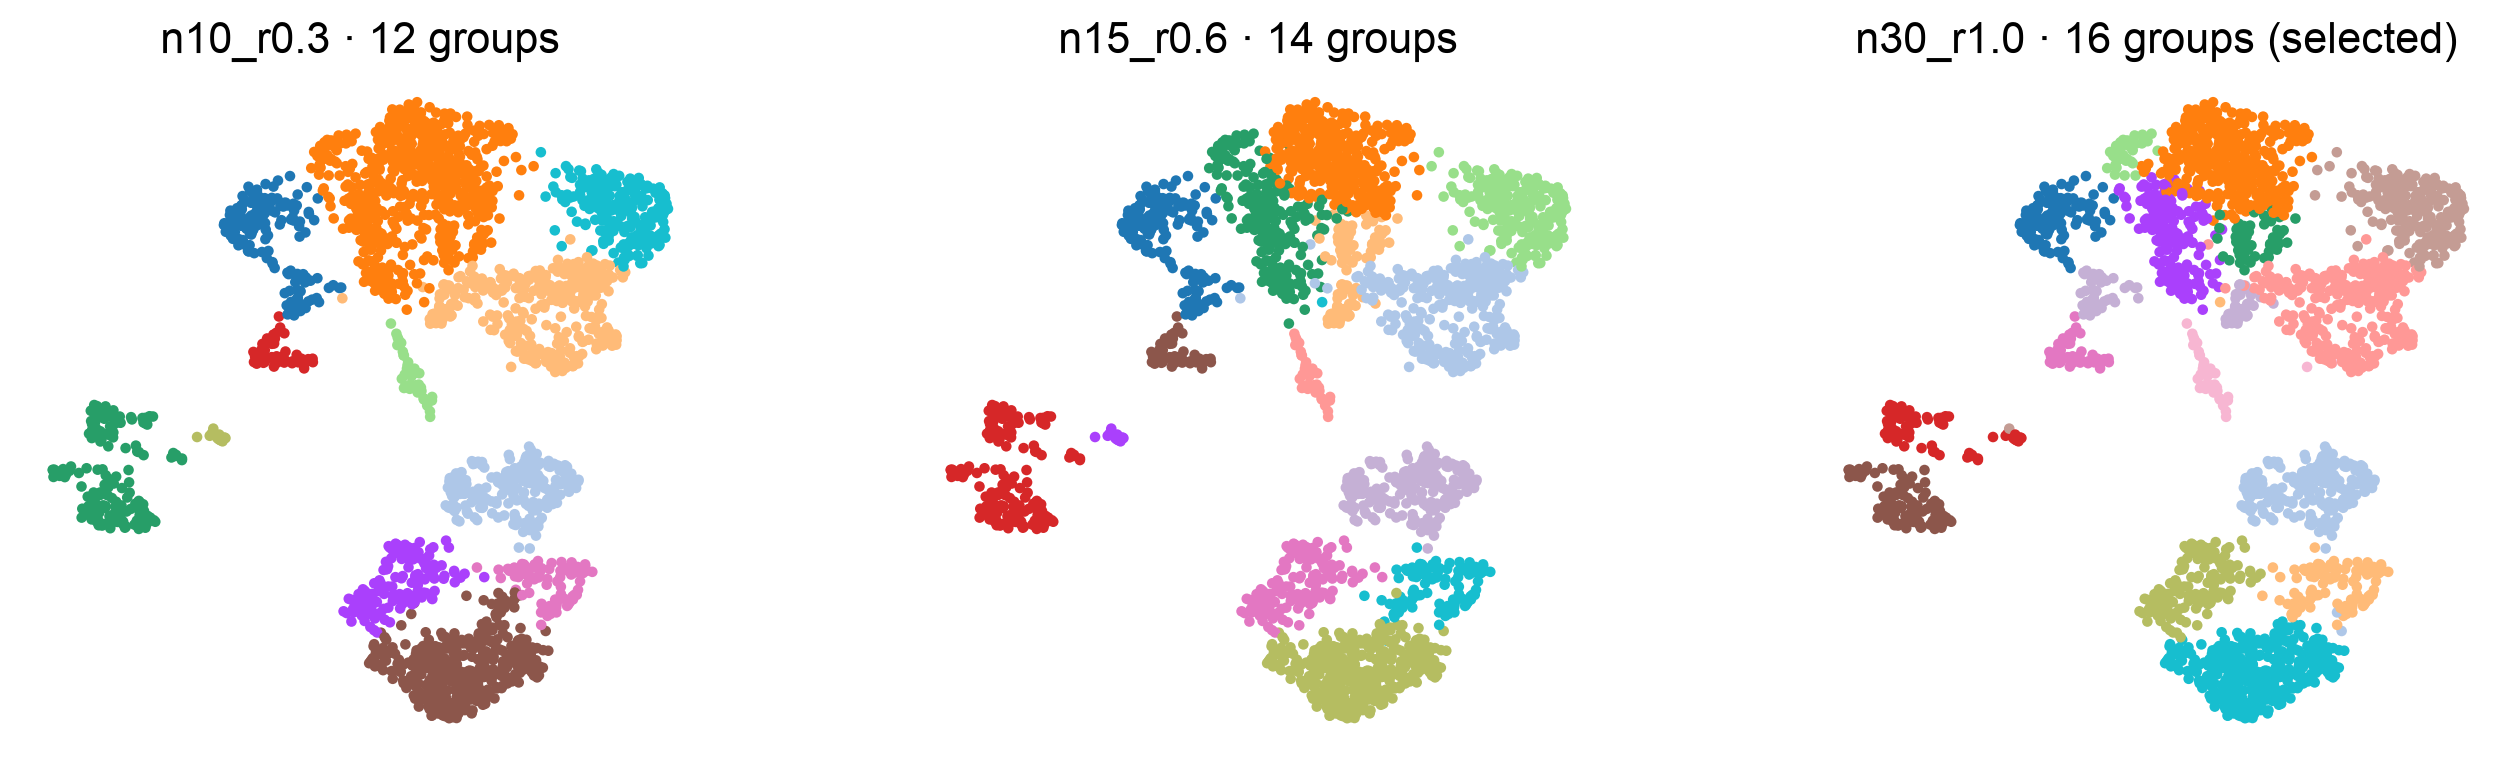

In [4]:
small_fraction = 0.005
size_rows = []
for key in keys:
    sizes = adata.obs[key].value_counts()
    sizes = sizes.loc[sizes.gt(0)]
    fractions = sizes / adata.n_obs
    size_rows.append({
        "Candidate": key,
        "Smallest group (cells)": int(sizes.min()),
        "Smallest group (%)": 100 * fractions.min(),
        "Groups below 0.5%": int(fractions.lt(small_fraction).sum()),
    })
display(pd.DataFrame(size_rows).round(3))

# One UMAP from the fixed 15-neighbor display graph for all three panels.
sc.tl.umap(adata, random_state=0)
titles = [f"{key} · {adata.obs[key].nunique()} groups" for key in keys]
titles[keys.index(winner['groupby'])] += " (selected)"
sc.pl.umap(adata, color=keys, title=titles, legend_loc="none")

**Read the maps.** Cell positions are identical across panels. Compare which cells are grouped together under each candidate. Colors identify groups within each panel independently. For a narrowly selected candidate, inspect which subdivisions it adds and whether they contain enough cells for your downstream question.

## Apply the comparison to your own AnnData

Start with one AnnData object. Store each candidate's labels in a separate `obs` column on the same cells, and provide one common molecular representation in `obsm`. The example runs on the teaching data. Change the input object, candidate column names, embedding key and per-group cost for your own comparison. You can regenerate the labels in your preferred software before using this cell.

In [5]:
user_adata = adata  # Replace with sc.read_h5ad("my_sample.h5ad").
grouping_columns = ["n10_r0.3", "n15_r0.6", "n30_r1.0"]  # Your candidates in .obs.
embedding = "X_pca"  # Your common molecular representation in .obsm.
target_delta = 0.05

user_result = gauge.evaluate(
    user_adata, groupby=grouping_columns, views={"molecular": {"obsm": embedding}},
    n_splits=5, random_state=0, aggregation="fold_mean",
)
user_selection = gauge.select(user_result, view="molecular", delta=target_delta)
display(user_selection.table[["groupby", "n_groups", "itca", "itca_plus", "selected"]].round(6))

,groupby,n_groups,itca,itca_plus,selected
0,n10_r0.3,12,2.053440,1.453440,False
1,n15_r0.6,14,2.305396,1.605396,False
2,n30_r1.0,16,2.414547,1.614547,True


## Go further

[Paper reproduction](../../docs/paper-reproduction.md) tracks the full Figure 7 workflow search and larger-scale evaluation. This tutorial compares three fixed settings on the smaller teaching asset.

[Use GAUGE with your agent](../../docs/agents.md) with the `vasculature` data or your own AnnData. Give the agent the candidate label columns and the common molecular representation. Ask for a raw and penalized score comparison, the margin to the runner-up, and a separate group-size check.